# Cyber-stress test d'un système financier fictif
### De la cartographie des dépendances à l'impact prudentiel (CET1 / LCR)

---

**Question posée.** Si un acteur critique (cloud, infrastructure de paiement, banque systémique) subit une cyberattaque, **jusqu'où l'incident se propage-t-il, et combien de banques franchissent leurs seuils prudentiels ?**

**Démarche.** Cinq étapes, chacune alimentant la suivante :

| # | Étape | Question | Résultat principal |
|---|---|---|---|
| 1 | [Cartographie](#etape1) | Qui dépend de qui ? | Graphe orienté de 16 acteurs, CSV, figure 1 |
| 2 | [Analyse de structure](#etape2) | Quels acteurs sont structurellement critiques ? | PageRank, intermédiarité, concentrations, SPOF |
| 3 | [Propagation](#etape3) | Jusqu'où un choc se diffuse-t-il ? | Taux de contagion par nœud (Monte-Carlo, 3 scénarios MITRE ATT&CK) |
| 4 | [Impact financier](#etape4) | Quelles pertes CET1 / LCR ? | Ratios avant / après, seuils franchis |
| 5 | [Sensibilité et recommandations](#etape5) | Quelles hypothèses comptent, quelles mesures aident ? | Courbes de sensibilité, comparaison de 2 mesures |

> **Toutes les données sont fictives.** 

### Conventions utilisées dans tout le notebook

- **Sens des arcs** : `A → B` signifie « si A tombe, B est impacté » (le sens va du *fournisseur* vers le *client*). PageRank, propagation et sensibilité en dépendent.
- **Échelles** : dépendance et substituabilité dans [0, 1] ; maturité cyber de 1 (faible) à 5 (excellente) ; RTO et vitesse de propagation en **heures**.
- **Reproductibilité** : graine aléatoire fixée (`SEED = 42`). Relancer le notebook redonne les mêmes résultats.

### Mode d'emploi
Installer les dépendances (une seule fois, dans un terminal) : `pip install networkx pandas numpy matplotlib scipy jupyter`

## 0. Configuration

In [1]:
import os, heapq
from io import StringIO

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import Markdown, display

# --- Paramètres globaux ---------------------------------------------------
SEED       = 42      # graine aléatoire (reproductibilité)
N_SIM      = 1000    # tirages Monte-Carlo par scénario
SEUIL_CET1 = 10.5    # seuil CET1 simplifié, en %
SEUIL_LCR  = 100     # seuil LCR, en %

# --- Dossiers et style des figures -----------------------------------------
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Palette : une couleur par famille d'acteurs
COULEURS = {"bank": "#378ADD", "fmi": "#E24B4A", "cloud": "#1D9E75", "it": "#1D9E75",
            "fintech": "#EF9F27", "insurer": "#7F77DD", "telecom": "#888780"}

<a id="etape1"></a>
# Étape 1 — Cartographie v1

**Objectif.** Construire la carte du système : 16 acteurs et leurs dépendances, sous forme d'un graphe orienté.

## 1.1 Les nœuds (acteurs)

| Colonne | Signification |
|---|---|
| `id` | Identifiant court (B = banque, PAY / SET = infrastructures, CLD = cloud, IT = prestataire IT, FT = fintech, INS = assureur, TEL = télécom) |
| `type` | Famille d'acteur (`fmi` = infrastructure de marché financier) |
| `maturity` | **Maturité cyber**, de 1 à 5 (inspirée du NIST CSF). Plus elle est basse, plus l'acteur est facile à atteindre |
| `exposure_pct` | Poids dans le système (part de marché pour les banques, 0 pour les autres). B1 pèse 30 % : c'est la banque systémique |
| `rto_h` | *Recovery Time Objective* : durée en heures nécessaire pour redémarrer après une panne |

Les maturités sont volontairement **hétérogènes** : des valeurs uniformes rendraient les scénarios plats.

In [2]:
nodes_csv = '''id,name,type,maturity,exposure_pct,rto_h
B1,Banque Systémique,bank,4,30,8
B2,Banque Nationale,bank,3,20,12
B3,Banque Régionale A,bank,3,15,12
B4,Banque Régionale B,bank,2,12,24
B5,Banque Digitale,bank,3,10,6
B6,Banque Mutualiste,bank,2,13,24
PAY,Infra Paiement,fmi,4,0,2
SET,Infra Règlement-Titres,fmi,4,0,4
CLD1,Cloud Commun,cloud,3,0,6
CLD2,Cloud Secondaire,cloud,3,0,8
IT1,Prestataire Core Banking,it,2,0,12
FT1,Fintech Paiement,fintech,2,0,12
FT2,Fintech Crédit,fintech,2,0,24
INS1,Assureur,insurer,3,0,24
TEL1,Télécom A,telecom,3,0,4
TEL2,Télécom B,telecom,2,0,6
'''
nodes = pd.read_csv(StringIO(nodes_csv))
nodes

,id,name,type,maturity,exposure_pct,rto_h
0,B1,Banque Systémique,bank,4,30,8
1,B2,Banque Nationale,bank,3,20,12
2,B3,Banque Régionale A,bank,3,15,12
3,B4,Banque Régionale B,bank,2,12,24
4,B5,Banque Digitale,bank,3,10,6
5,B6,Banque Mutualiste,bank,2,13,24
6,PAY,Infra Paiement,fmi,4,0,2
7,SET,Infra Règlement-Titres,fmi,4,0,4
8,CLD1,Cloud Commun,cloud,3,0,6
9,CLD2,Cloud Secondaire,cloud,3,0,8


## 1.2 Les liens (dépendances)

Chaque ligne est une flèche `source → target`.

| Colonne | Signification |
|---|---|
| `dependency` | À quel point la cible a besoin de la source (0 à 1) |
| `substitutability` | À quel point on peut remplacer la source (0 = impossible, 1 = trivial) |
| `speed_h` | Délai en heures entre la panne de la source et l'impact sur la cible |
| `type` | `technological`, `operational` ou `financial` |

Trois logiques de liens :

1. **Cloud, IT, télécoms → banques et fintechs** (technologique) : dépendance forte, substitution difficile.
2. **PAY et SET → banques** (opérationnel) : dépendance très forte, quasi aucune alternative.
3. **Banque → banque** (financier) : dépendance plus faible, propagation lente (24 h).

> Un lien est **dangereux** quand la dépendance est haute *et* la substituabilité basse.

In [3]:
links_csv = '''source,target,dependency,substitutability,speed_h,type
CLD1,B1,0.8,0.2,1,technological
CLD1,B2,0.7,0.3,1,technological
CLD1,B3,0.6,0.3,1,technological
CLD1,FT1,0.9,0.2,0.5,technological
CLD1,FT2,0.8,0.3,0.5,technological
CLD1,PAY,0.5,0.3,1,technological
CLD2,B4,0.7,0.4,1,technological
CLD2,B5,0.6,0.5,1,technological
CLD2,B6,0.6,0.5,1,technological
CLD2,INS1,0.7,0.4,1,technological
IT1,B1,0.5,0.2,2,technological
IT1,B2,0.6,0.3,2,technological
IT1,B4,0.5,0.4,2,technological
IT1,B6,0.4,0.5,2,technological
PAY,B1,0.9,0.1,0.5,operational
PAY,B2,0.9,0.1,0.5,operational
PAY,B3,0.9,0.1,0.5,operational
PAY,B4,0.9,0.1,0.5,operational
PAY,B5,0.8,0.1,0.5,operational
PAY,B6,0.8,0.1,0.5,operational
PAY,FT1,0.8,0.2,0.5,operational
PAY,FT2,0.6,0.2,0.5,operational
SET,B1,0.7,0.2,2,operational
SET,B2,0.6,0.2,2,operational
SET,B3,0.5,0.3,2,operational
SET,INS1,0.4,0.3,2,operational
TEL1,PAY,0.4,0.5,1,technological
TEL1,B1,0.3,0.6,1,technological
TEL1,CLD1,0.3,0.5,1,technological
TEL2,SET,0.4,0.5,1,technological
TEL2,CLD2,0.3,0.5,1,technological
TEL2,B5,0.3,0.6,1,technological
B1,B2,0.4,0.5,24,financial
B1,B3,0.3,0.5,24,financial
B1,B4,0.3,0.5,24,financial
B1,INS1,0.2,0.6,24,financial
B2,B3,0.3,0.5,24,financial
B2,B6,0.2,0.6,24,financial
'''
links = pd.read_csv(StringIO(links_csv))
links

,source,target,dependency,substitutability,speed_h,type
0,CLD1,B1,0.8,0.2,1.0,technological
1,CLD1,B2,0.7,0.3,1.0,technological
2,CLD1,B3,0.6,0.3,1.0,technological
3,CLD1,FT1,0.9,0.2,0.5,technological
4,CLD1,FT2,0.8,0.3,0.5,technological
5,CLD1,PAY,0.5,0.3,1.0,technological
6,CLD2,B4,0.7,0.4,1.0,technological
7,CLD2,B5,0.6,0.5,1.0,technological
8,CLD2,B6,0.6,0.5,1.0,technological
9,CLD2,INS1,0.7,0.4,1.0,technological


## 1.3 Contrôle de cohérence

On vérifie qu'il n'y a pas d'erreur de saisie : liens orphelins (faute de frappe dans un identifiant), valeurs hors bornes, doublons, auto-boucles, nœuds isolés, et deux contrôles métier (B1 pèse ≈ 30 %, les expositions des banques totalisent 100 %).

In [4]:
def check(nodes, links):
    "Contrôle de cohérence des données. Affiche le diagnostic et renvoie True si tout est OK."
    errs, ids = [], set(nodes.id)

    # Liens orphelins
    for col in ("source", "target"):
        bad = set(links[col]) - ids
        if bad:
            errs.append(f"Liens orphelins ({col}) : {bad}")

    # Bornes
    for col in ("dependency", "substitutability"):
        if not links[col].between(0, 1).all():
            errs.append(f"{col} hors [0, 1]")
    if not nodes.maturity.between(1, 5).all():
        errs.append("maturity hors [1, 5]")
    if (nodes.rto_h <= 0).any() or (links.speed_h <= 0).any():
        errs.append("RTO ou vitesse <= 0")

    # Doublons, auto-boucles, nœuds isolés
    if links.duplicated(["source", "target"]).any():
        errs.append("Liens en double")
    if (links.source == links.target).any():
        errs.append("Auto-boucles")
    isoles = ids - set(links.source) - set(links.target)
    if isoles:
        errs.append(f"Nœuds isolés : {isoles}")

    # Cohérence métier
    if abs(nodes.loc[nodes.id == "B1", "exposure_pct"].iloc[0] - 30) > 3:
        errs.append("B1 doit peser ~30 %")
    if abs(nodes.loc[nodes.type == "bank", "exposure_pct"].sum() - 100) > 0.5:
        errs.append("Les expositions des banques doivent totaliser 100 %")

    print("Contrôle de cohérence : OK" if not errs else "ERREURS :\n - " + "\n - ".join(errs))
    return not errs

_ = check(nodes, links)

Contrôle de cohérence : OK


## 1.4 Construction du graphe orienté

Un `DiGraph` networkx : chaque acteur est ajouté avec ses attributs (`add_node`), chaque dépendance avec les siens (`add_edge`).

In [5]:
def construire_graphe(nodes, links):
    "Construit le graphe orienté fournisseur → client avec tous les attributs."
    G = nx.DiGraph()
    for _, r in nodes.iterrows():
        G.add_node(r.id, **r.drop("id").to_dict())
    for _, r in links.iterrows():
        G.add_edge(r.source, r.target, **r.drop(["source", "target"]).to_dict())
    return G

G = construire_graphe(nodes, links)
print(f"Graphe créé : {G.number_of_nodes()} nœuds, {G.number_of_edges()} arcs")

Graphe créé : 16 nœuds, 38 arcs


## 1.5 Visualisation (figure 1)

Lecture du graphe : la **couleur** indique la famille d'acteur, la **taille** du nœud l'exposition, l'**épaisseur** de la flèche la dépendance.

**Point d'arrêt** : PAY, CLD1 et B1 doivent apparaître comme des hubs. Sinon, revoir les liens avant d'avancer.

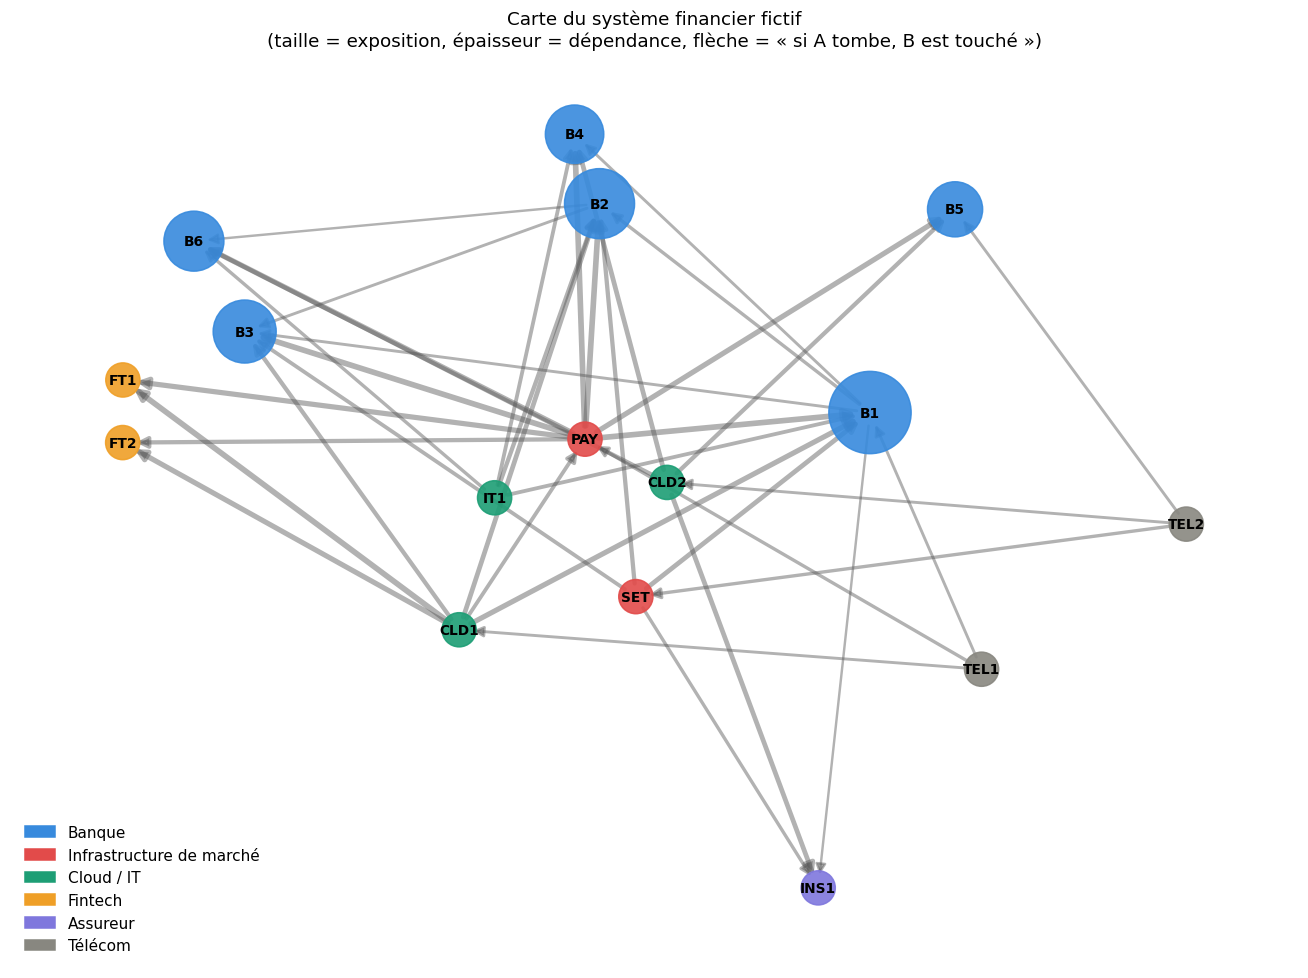

In [6]:
pos = nx.kamada_kawai_layout(G)

# Des nœuds aux connexions identiques (ex. FT1 / FT2) se superposeraient : on les écarte légèrement
ids_ = list(pos)
for i, a in enumerate(ids_):
    for b in ids_[i + 1:]:
        if np.linalg.norm(pos[a] - pos[b]) < 0.1:
            pos[a] = pos[a] + np.array([0.0, 0.07])
            pos[b] = pos[b] - np.array([0.0, 0.07])

fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx_nodes(
    G, pos, ax=ax, alpha=0.9,
    node_color=[COULEURS[G.nodes[n]["type"]] for n in G],
    node_size=[500 + 80 * G.nodes[n]["exposure_pct"] for n in G])
nx.draw_networkx_edges(
    G, pos, ax=ax, arrowsize=14, alpha=0.45, edge_color="#555555",
    width=[1 + 3 * G[u][v]["dependency"] for u, v in G.edges])
nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_weight="bold")

legende = [Patch(color=COULEURS["bank"], label="Banque"),
           Patch(color=COULEURS["fmi"], label="Infrastructure de marché"),
           Patch(color=COULEURS["cloud"], label="Cloud / IT"),
           Patch(color=COULEURS["fintech"], label="Fintech"),
           Patch(color=COULEURS["insurer"], label="Assureur"),
           Patch(color=COULEURS["telecom"], label="Télécom")]
ax.legend(handles=legende, loc="lower left", frameon=False)
ax.set_title("Carte du système financier fictif\n(taille = exposition, épaisseur = dépendance, flèche = « si A tombe, B est touché »)")
ax.axis("off")
plt.tight_layout()
plt.savefig("figures/fig1_graphe.png", dpi=200, bbox_inches="tight")
plt.show()

## 1.6 Export des données

In [7]:
nodes.to_csv("data/nodes.csv", index=False)
links.to_csv("data/links.csv", index=False)
print("Fichiers exportés : data/nodes.csv, data/links.csv, figures/fig1_graphe.png")

Fichiers exportés : data/nodes.csv, data/links.csv, figures/fig1_graphe.png


<a id="etape2"></a>
# Étape 2 — Analyse de structure

**Objectif.** Identifier les acteurs dont la chute serait la plus dangereuse. Quatre outils, quatre angles de vue :

| Outil | Question posée | Lecture |
|---|---|---|
| **PageRank** (graphe inversé) | Qui est tout en haut de la chaîne de dépendances ? | Score élevé = fournisseur dont dépendent des acteurs eux-mêmes importants |
| **Intermédiarité** (*betweenness*) | Qui sert de relais ? | Score élevé = beaucoup de chemins de propagation traversent ce nœud |
| **Concentration** | Combien de banques sont touchées si ce nœud tombe ? | Comparer lien direct et atteignable par chaîne |
| **SPOF** (*single point of failure*) | Où les liens sont-ils forts et non remplaçables ? | Dépendance ≥ 0,7 **et** substituabilité ≤ 0,3 |

> **Point technique important.** Le PageRank de networkx récompense les nœuds qui *reçoivent* beaucoup de flèches, donc ici les banques. Pour mesurer l'importance des *fournisseurs*, on le calcule sur le graphe inversé (`G.reverse()`).

In [8]:
# 2.1 PageRank sur le graphe inversé : met en avant les fournisseurs critiques
pr = pd.Series(nx.pagerank(G.reverse(), weight="dependency", alpha=0.85), name="pagerank")

# 2.2 Intermédiarité : nœuds servant de relais de propagation
btw = pd.Series(nx.betweenness_centrality(G), name="betweenness")

# 2.3 Concentration : banques touchées en direct et par chaîne de dépendances
banks = nodes.loc[nodes.type == "bank", "id"].tolist()
conc = pd.DataFrame({
    "banques_directes":     {n: sum(G.has_edge(n, b) for b in banks) for n in G},
    "banques_atteignables": {n: len(nx.descendants(G, n) & set(banks)) for n in G},
})

# 2.4 SPOF : dépendance forte et substituabilité faible
spof = (links.query("dependency >= 0.7 and substitutability <= 0.3")
             .sort_values("dependency", ascending=False))

print(f"{len(spof)} liens critiques (SPOF) :")
spof.reset_index(drop=True)

12 liens critiques (SPOF) :


,source,target,dependency,substitutability,speed_h,type
0,CLD1,FT1,0.9,0.2,0.5,technological
1,PAY,B3,0.9,0.1,0.5,operational
2,PAY,B2,0.9,0.1,0.5,operational
3,PAY,B1,0.9,0.1,0.5,operational
4,PAY,B4,0.9,0.1,0.5,operational
5,PAY,B5,0.8,0.1,0.5,operational
6,CLD1,B1,0.8,0.2,1.0,technological
7,CLD1,FT2,0.8,0.3,0.5,technological
8,PAY,FT1,0.8,0.2,0.5,operational
9,PAY,B6,0.8,0.1,0.5,operational


## 2.5 Tableau de synthèse

In [9]:
summary = pd.concat([pr, btw, conc], axis=1)
summary["nb_spof_sortants"] = (spof.groupby("source").size()
                                   .reindex(summary.index).fillna(0).astype(int))
summary = summary.sort_values("pagerank", ascending=False).round(3)

summary.to_csv("data/structure_metrics.csv")
spof.to_csv("data/spof.csv", index=False)
summary

,pagerank,betweenness,banques_directes,banques_atteignables,nb_spof_sortants
TEL1,0.182,0.000,1,6,0
TEL2,0.135,0.000,1,6,0
CLD1,0.128,0.008,3,6,4
PAY,0.108,0.029,6,6,7
CLD2,0.065,0.012,3,3,0
SET,0.054,0.017,3,5,1
IT1,0.050,0.000,4,5,0
B1,0.042,0.034,3,4,0
B2,0.034,0.014,2,2,0
B6,0.029,0.000,0,0,0


## 2.6 Visualisation (figure 2)

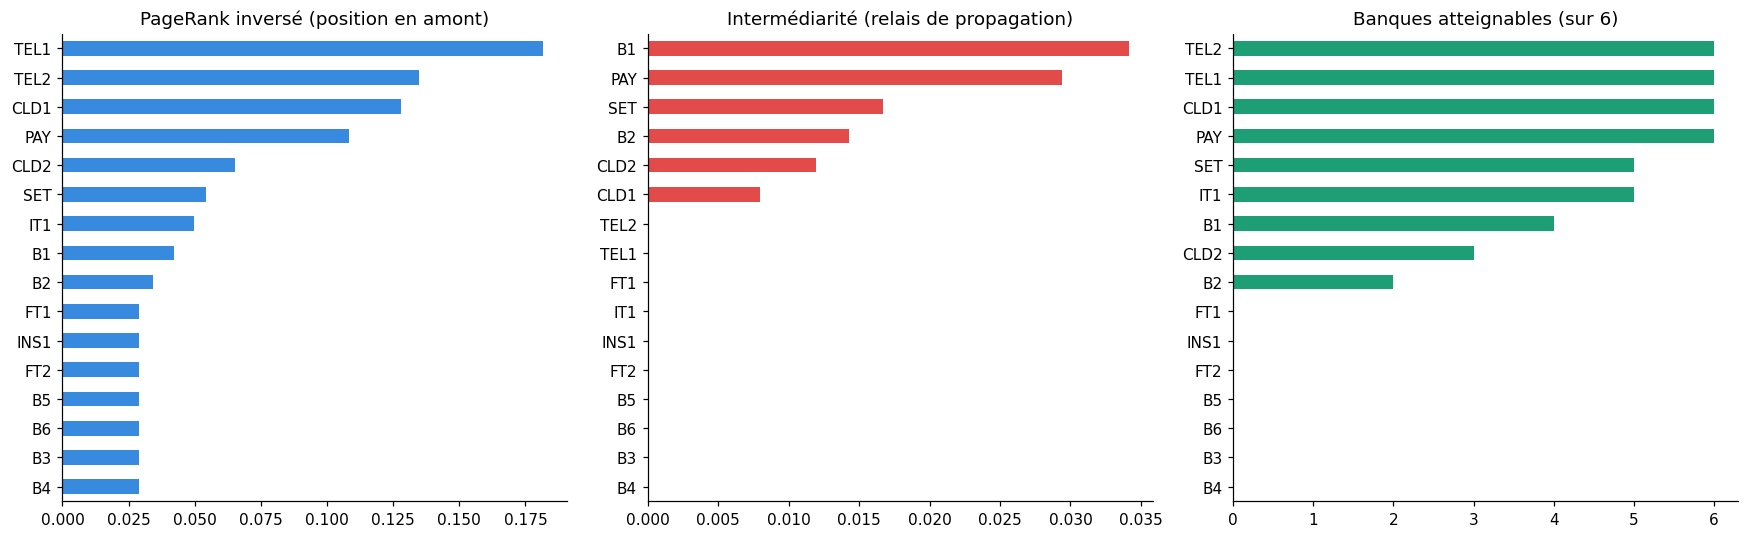

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

pr.sort_values().plot(kind="barh", ax=axes[0], color="#378ADD")
axes[0].set_title("PageRank inversé (position en amont)")

btw.sort_values().plot(kind="barh", ax=axes[1], color="#E24B4A")
axes[1].set_title("Intermédiarité (relais de propagation)")

conc["banques_atteignables"].sort_values().plot(kind="barh", ax=axes[2], color="#1D9E75")
axes[2].set_title("Banques atteignables (sur 6)")

plt.tight_layout()
plt.savefig("figures/fig2_structure.png", dpi=200, bbox_inches="tight")
plt.show()

## 2.7 Lecture des résultats : angles morts et concentrations

- **Concentration visible : PAY.** Il dessert directement les 6 banques et porte 7 des 12 liens critiques. C'est le point de défaillance unique le plus évident. CLD1 porte 4 liens critiques, SET 1.
- **Risques cachés : TEL1, TEL2, CLD1.** Ils n'ont que 1 à 3 banques en lien direct, mais atteignent chacun les 6 banques par propagation (via PAY, SET ou CLD2). L'écart *directes / atteignables* révèle ce risque.
- **PageRank : TEL1 arrive premier**, car il est tout en haut de plusieurs chaînes. Mais ses liens sont faibles (dépendance 0,3–0,4, substituabilité 0,5–0,6) et il ne porte aucun SPOF : le risque est **structurel, pas immédiat**. Le PageRank ne regarde pas l'intensité des liens, d'où la nécessité de l'étape 3.
- **Angle mort : IT1** (prestataire core banking, maturité 2). Il touche 4 banques en direct et 5 au total, mais n'apparaît dans aucun SPOF au seuil retenu : il passerait inaperçu dans une analyse centrée sur les SPOF.
- **Relais de contagion : B1** a l'intermédiarité la plus élevée : elle reçoit des pannes (cloud, paiement) et les retransmet vers B2, B3, B4 et INS1 par les liens financiers. L'intermédiarité d'un nœud sans fournisseur (TEL1, TEL2) vaut 0 : les chemins en *partent* sans jamais le *traverser*.
- **Les 0,029 en bas du PageRank** (B3 à B6, FT1, FT2, INS1) sont la valeur plancher : ces clients finaux ne sont le fournisseur de personne.


<a id="etape3"></a>
# Étape 3 — Propagation par simulation Monte-Carlo

**Objectif.** Estimer, pour chaque acteur, la **probabilité d'être touché** et le **délai moyen** avant impact, pour trois scénarios de choc.

## 3.1 Le modèle de transmission

Quand un nœud `u` est touché, chaque arc `u → v` transmet l'incident avec la probabilité :

$$p_{u \to v} \;=\; \text{dépendance} \times (1 - \text{substituabilité}) \times \text{vulnérabilité}(v)$$

avec une vulnérabilité décroissante de la maturité cyber de la cible :

$$\text{vulnérabilité}(m) = \frac{6 - m}{5} \qquad (m = 1 \Rightarrow 1{,}0 \;;\; m = 5 \Rightarrow 0{,}2)$$

Interprétation : plus `v` a besoin de `u`, moins il peut le remplacer, et moins il est bien protégé, plus la transmission est probable.

## 3.2 L'algorithme (cascade à propagation indépendante)

Répété `N_SIM` fois par scénario :

1. Le nœud choc est touché à t = 0.
2. Dès qu'un nœud touché est traité, on tire pour chacun de ses arcs sortants un nombre `U(0,1)` ; si `U < p`, la cible est touchée à l'instant `t_source + speed_h`.
3. Les nœuds sont traités **par ordre de temps croissant** (file de priorité), si bien que le temps enregistré est bien le plus court chemin d'infection.
4. On enregistre pour chaque nœud s'il a été touché et quand.

Le **taux de contagion** d'un nœud est la fraction des tirages où il est touché. Le **temps moyen** est calculé sur les tirages où il l'est.

In [11]:
def vulnerabilite(maturite):
    "Vulnérabilité d'une cible selon sa maturité cyber (1 -> 1,0 ; 5 -> 0,2)."
    return (6 - maturite) / 5

def proba_transmission(G, u, v):
    "Probabilité que l'incident passe de u à v."
    e = G[u][v]
    return e["dependency"] * (1 - e["substitutability"]) * vulnerabilite(G.nodes[v]["maturity"])

def simuler(G, noeud_choc, n_sim=N_SIM, graine=SEED):
    '''
    Monte-Carlo de la propagation d'un choc initial sur `noeud_choc`.
    Renvoie un DataFrame indexé par nœud : taux_contagion, temps_moyen_h.
    La graine est la même pour tous les appels : les comparaisons « avant / après »
    de l'étape 5 reposent donc sur les mêmes tirages aléatoires.
    '''
    rng = np.random.default_rng(graine)
    p = {(u, v): proba_transmission(G, u, v) for u, v in G.edges}
    n_touche = dict.fromkeys(G.nodes, 0)
    temps = {n: [] for n in G.nodes}

    for _ in range(n_sim):
        arrivee = {noeud_choc: 0.0}
        file = [(0.0, noeud_choc)]
        traites = set()
        while file:
            t_u, u = heapq.heappop(file)          # nœud touché le plus tôt
            if u in traites:                       # entrée obsolète de la file
                continue
            traites.add(u)
            for v in G.successors(u):
                if v in traites:
                    continue
                if rng.random() < p[(u, v)]:       # transmission réussie ?
                    t_v = t_u + G[u][v]["speed_h"]
                    if t_v < arrivee.get(v, np.inf):
                        arrivee[v] = t_v
                        heapq.heappush(file, (t_v, v))
        for n, t in arrivee.items():
            n_touche[n] += 1
            temps[n].append(t)

    return pd.DataFrame({
        "taux_contagion": {n: n_touche[n] / n_sim for n in G.nodes},
        "temps_moyen_h":  {n: float(np.mean(temps[n])) if temps[n] else np.nan for n in G.nodes},
    })

## 3.3 Contrôle de calibrage

Avant de simuler, on regarde les probabilités de transmission. Si elles sont toutes inférieures à 0,1, aucune contagion n'apparaîtra ; si toutes sont proches de 1, le modèle sera plat. On vise **20 à 60 %** sur les arcs critiques.

In [12]:
p_arcs = links[["source", "target", "type"]].copy()
p_arcs["p_transmission"] = [proba_transmission(G, u, v) for u, v in zip(links.source, links.target)]
p_arcs = p_arcs.sort_values("p_transmission", ascending=False)

print("Distribution des probabilités de transmission :")
print(p_arcs["p_transmission"].describe().round(3).to_string())
print("\nLes 8 arcs les plus transmetteurs :")
p_arcs.head(8).round(3).reset_index(drop=True)

Distribution des probabilités de transmission :
count    38.000
mean      0.250
std       0.168
min       0.048
25%       0.098
50%       0.232
75%       0.333
max       0.648

Les 8 arcs les plus transmetteurs :


,source,target,type,p_transmission
0,PAY,B4,operational,0.648
1,CLD1,FT1,technological,0.576
2,PAY,B6,operational,0.576
3,PAY,FT1,operational,0.512
4,PAY,B2,operational,0.486
5,PAY,B3,operational,0.486
6,CLD1,FT2,technological,0.448
7,PAY,B5,operational,0.432


## 3.4 Les trois scénarios (mappés MITRE ATT&CK)

| Scénario | Technique | Nœud choc | Intuition |
|---|---|---|---|
| `T1195_cloud` | T1195 — *Supply Chain Compromise* | CLD1 | Compromission du cloud commun |
| `T1498_pay` | T1498 — *Network Denial of Service* | PAY | Déni de service sur l'infrastructure de paiement |
| `T1486_b1` | T1486 — *Data Encrypted for Impact* | B1 | Rançongiciel sur la banque systémique |

Le nœud choc est touché avec certitude (taux = 100 %) : on mesure la **conséquence** d'une attaque réussie, pas sa probabilité.

In [13]:
scenarios = {
    "T1195_cloud": {"seed": "CLD1", "name": "T1195 – Compromission Cloud Commun"},
    "T1498_pay":   {"seed": "PAY",  "name": "T1498 – Déni de service Infra Paiement"},
    "T1486_b1":    {"seed": "B1",   "name": "T1486 – Rançongiciel Banque Systémique"},
}

contagion = {sid: simuler(G, sc["seed"]) for sid, sc in scenarios.items()}

for sid, df in contagion.items():
    df.sort_values("taux_contagion", ascending=False).to_csv(f"data/contagion_{sid}.csv")

# Tableau comparatif : taux de contagion par nœud et par scénario
tab_contagion = pd.DataFrame({sid: df["taux_contagion"] for sid, df in contagion.items()})
tab_contagion = tab_contagion.sort_values(list(tab_contagion.columns), ascending=False)
tab_contagion.round(3)

,T1195_cloud,T1498_pay,T1486_b1
CLD1,1.000,0.000,0.000
FT1,0.614,0.522,0.000
FT2,0.484,0.366,0.000
B2,0.371,0.497,0.133
B3,0.324,0.521,0.096
B1,0.309,0.331,1.000
PAY,0.144,1.000,0.000
B4,0.133,0.702,0.116
B6,0.101,0.589,0.007
B5,0.068,0.442,0.000


## 3.5 Délais de propagation

Temps moyen (en heures) avant que chaque nœud soit touché, **conditionnellement** au fait qu'il le soit. `NaN` signifie que le nœud n'est jamais touché dans ce scénario.

In [14]:
tab_temps = pd.DataFrame({sid: df["temps_moyen_h"] for sid, df in contagion.items()})
tab_temps.loc[tab_contagion.index].round(1)

,T1195_cloud,T1498_pay,T1486_b1
CLD1,0.0,NaN,NaN
FT1,0.5,0.5,NaN
FT2,0.6,0.5,NaN
B2,2.3,1.5,24.0
B3,3.8,2.3,26.8
B1,1.1,0.5,0.0
PAY,1.0,0.0,NaN
B4,5.9,0.9,24.0
B6,5.7,1.2,48.0
B5,1.5,0.5,NaN


## 3.6 Visualisation (figure 3)

Le nœud choc est en rouge.

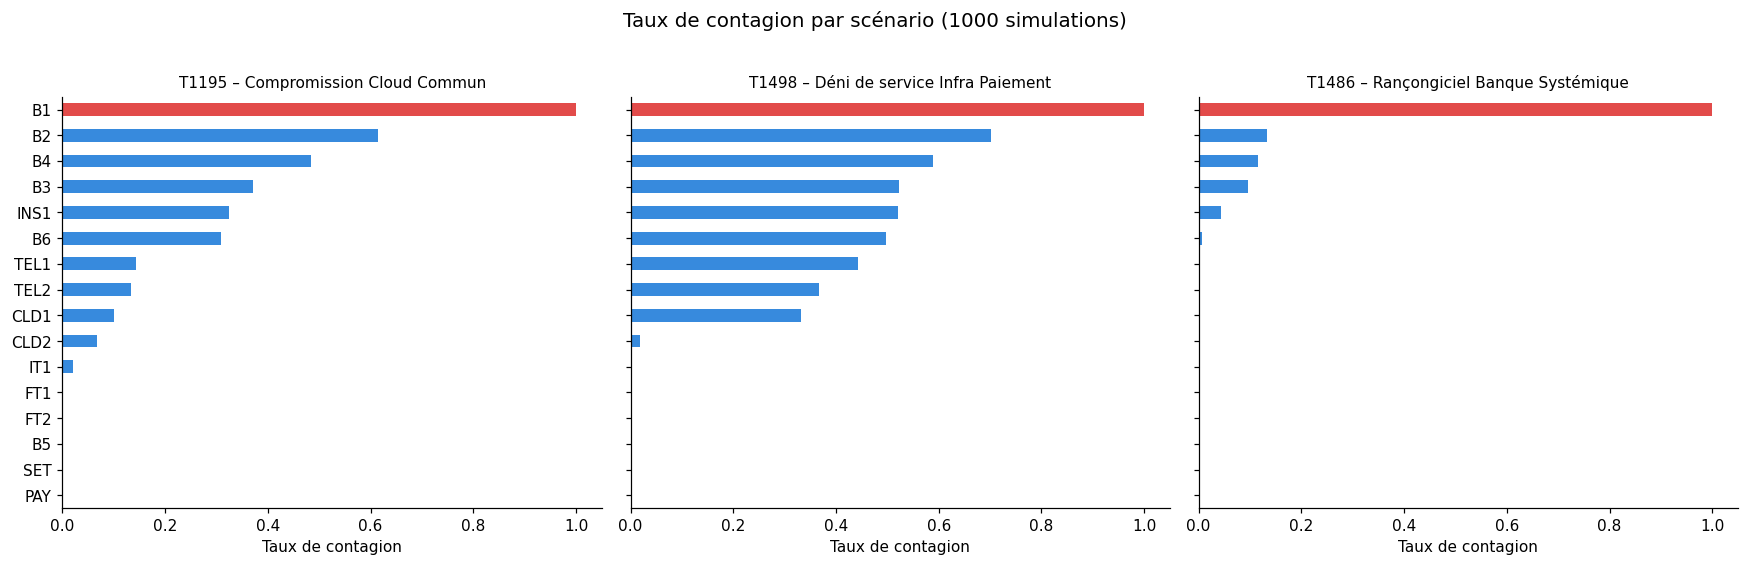

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (sid, df) in zip(axes, contagion.items()):
    s = df["taux_contagion"].sort_values()
    s.plot(kind="barh", ax=ax,
           color=["#E24B4A" if n == scenarios[sid]["seed"] else "#378ADD" for n in s.index])
    ax.set_title(scenarios[sid]["name"], fontsize=10)
    ax.set_xlabel("Taux de contagion")
    ax.set_xlim(0, 1.05)
plt.suptitle(f"Taux de contagion par scénario ({N_SIM} simulations)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("figures/fig3_contagion.png", dpi=200, bbox_inches="tight")
plt.show()

## 3.7 Synthèse de la propagation

Deux indicateurs agrégés par scénario : le **nombre espéré de banques touchées** (somme des taux de contagion des 6 banques) et la **part de marché espérée touchée** (somme des taux pondérés par l'exposition). Le second tient compte du fait que toucher B1 pèse bien plus que toucher B5.

In [16]:
expo = nodes.set_index("id")["exposure_pct"]
synth_prop = pd.DataFrame({
    sc["name"]: {
        "Nœud choc": sc["seed"],
        "Banques touchées (espérance, sur 6)": contagion[sid].loc[banks, "taux_contagion"].sum(),
        "Part de marché touchée (espérance, %)": (contagion[sid].loc[banks, "taux_contagion"] * expo[banks]).sum(),
    } for sid, sc in scenarios.items()
}).T
synth_prop.iloc[:, 1:] = synth_prop.iloc[:, 1:].astype(float).round(2)
synth_prop

,Nœud choc,"Banques touchées (espérance, sur 6)","Part de marché touchée (espérance, %)"
T1195 – Compromission Cloud Commun,CLD1,1.31,25.14
T1498 – Déni de service Infra Paiement,PAY,3.08,48.19
T1486 – Rançongiciel Banque Systémique,B1,1.35,35.58


**Lecture.** Le déni de service sur PAY est le scénario le plus étendu : PAY dessert toutes les banques avec des liens forts et peu substituables. Le rançongiciel sur B1 se propage peu et lentement (liens financiers faibles, 24 h de délai), mais ses effets restent à mesurer à l'étape 4, car les délais comptent moins que les durées d'indisponibilité.

<a id="etape4"></a>
# Étape 4 — Table de correspondance et impact financier

**Objectif.** Traduire une indisponibilité en perte de capital (CET1) et de liquidité (LCR), puis détecter les seuils franchis.

## 4.1 Hypothèses de transposition

1. **Durée d'indisponibilité d'une banque touchée** = `max(RTO du nœud choc, RTO de la banque)`. La banque reste indisponible au moins jusqu'à la remise en service de la source de l'incident, et au moins le temps de son propre redémarrage.
2. **Table de correspondance** : la durée détermine une perte opérationnelle et des retraits de dépôts (ci-dessous).
3. **CET1 après** = CET1 avant − perte opérationnelle (en points de pourcentage).
4. **LCR après** = LCR avant × (1 − retraits %). Approximation simple : les retraits réduisent le LCR proportionnellement.
5. Pour tenir compte de la contagion, on calcule le **ratio conditionnel** (« si la banque est touchée ») et la **probabilité de franchissement** (= taux de contagion si un seuil est franchi, 0 sinon).

> **Pourquoi utiliser le RTO et non le délai de propagation ?** Le délai de propagation dit *quand* l'incident arrive, pas *combien de temps* la banque est arrêtée. Utiliser le délai donnerait un résultat inversé : plus l'incident arrive tard, plus la perte serait grande.

In [17]:
# Table de correspondance : (durée min, durée max, perte op. en pts de CET1, retraits en % des dépôts)
IMPACT_TABLE = pd.DataFrame(
    [(0, 4, 0.0, 0.0), (4, 12, 0.5, 2.0), (12, 24, 1.5, 5.0), (24, 48, 3.0, 10.0), (48, 999, 6.0, 20.0)],
    columns=["duree_min_h", "duree_max_h", "perte_op_pts_CET1", "retraits_pct_depots"])

def impact_depuis_duree(duree_h):
    "Renvoie (perte opérationnelle en pts de CET1, retraits en % des dépôts) pour une durée donnée."
    ligne = IMPACT_TABLE[(IMPACT_TABLE.duree_min_h <= duree_h) & (duree_h < IMPACT_TABLE.duree_max_h)].iloc[0]
    return ligne.perte_op_pts_CET1, ligne.retraits_pct_depots

IMPACT_TABLE

,duree_min_h,duree_max_h,perte_op_pts_CET1,retraits_pct_depots
0,0,4,0.0,0.0
1,4,12,0.5,2.0
2,12,24,1.5,5.0
3,24,48,3.0,10.0
4,48,999,6.0,20.0


## 4.2 Bilans fictifs des banques

In [18]:
bilans_csv = '''id,cet1_pct,lcr_pct,depots
B1,14.5,145,100
B2,13.2,132,60
B3,12.8,128,40
B4,11.5,115,25
B5,15.0,160,20
B6,12.0,120,30
'''
bilans = pd.read_csv(StringIO(bilans_csv)).set_index("id")
bilans["marge_CET1_pts"] = (bilans.cet1_pct - SEUIL_CET1).round(2)
bilans.to_csv("data/banks_balance.csv")
print(f"Seuils : CET1 < {SEUIL_CET1} %  |  LCR < {SEUIL_LCR} %")
bilans

Seuils : CET1 < 10.5 %  |  LCR < 100 %


,cet1_pct,lcr_pct,depots,marge_CET1_pts
id,,,,
B1,14.5,145,100,4.0
B2,13.2,132,60,2.7
B3,12.8,128,40,2.3
B4,11.5,115,25,1.0
B5,15.0,160,20,4.5
B6,12.0,120,30,1.5


La colonne `marge_CET1_pts` indique de combien de points de CET1 chaque banque peut perdre avant de franchir le seuil : B4 (1,0 pt) et B6 (1,5 pt) sont les plus fragiles. La colonne `depots` est informative ; elle n'intervient pas dans le LCR simplifié.

## 4.3 Calcul de l'impact par scénario

In [19]:
def impact_scenario(G, taux, noeud_choc):
    '''
    Impact prudentiel sur les 6 banques pour un choc donné.
    `taux` : Series des taux de contagion (issus de simuler()).
    '''
    rows = []
    for b in bilans.index:
        duree = max(G.nodes[noeud_choc]["rto_h"], G.nodes[b]["rto_h"])
        perte, retrait = impact_depuis_duree(duree)
        cet1_apres = bilans.loc[b, "cet1_pct"] - perte
        lcr_apres = bilans.loc[b, "lcr_pct"] * (1 - retrait / 100)
        rows.append({
            "banque": b, "proba_touchee": taux[b], "duree_h": duree,
            "perte_op_pts": perte, "retraits_pct": retrait,
            "CET1_avant": bilans.loc[b, "cet1_pct"], "CET1_apres": round(cet1_apres, 2),
            "LCR_avant": bilans.loc[b, "lcr_pct"], "LCR_apres": round(lcr_apres, 1),
            "franchit_CET1": cet1_apres < SEUIL_CET1, "franchit_LCR": lcr_apres < SEUIL_LCR,
        })
    df = pd.DataFrame(rows)
    df["proba_franchissement"] = df.proba_touchee * (df.franchit_CET1 | df.franchit_LCR)
    return df

def nb_banques_sous_seuil(df):
    "Espérance du nombre de banques sous au moins un seuil (somme des probabilités de franchissement)."
    return float(df["proba_franchissement"].sum())

impacts = {sid: impact_scenario(G, contagion[sid]["taux_contagion"], sc["seed"])
           for sid, sc in scenarios.items()}

for sid, df in impacts.items():
    df.to_csv(f"data/impact_{sid}.csv", index=False)
    display(Markdown(f"**{scenarios[sid]['name']}**"))
    display(df.drop(columns=["proba_franchissement"]).style.hide(axis="index").format(
        {"proba_touchee": "{:.0%}", "CET1_apres": "{:.2f}", "LCR_apres": "{:.1f}"}))

**T1195 – Compromission Cloud Commun**

banque,proba_touchee,duree_h,perte_op_pts,retraits_pct,CET1_avant,CET1_apres,LCR_avant,LCR_apres,franchit_CET1,franchit_LCR
B1,31%,8,0.500000,2.000000,14.500000,14.00,145,142.1,False,False
B2,37%,12,1.500000,5.000000,13.200000,11.70,132,125.4,False,False
B3,32%,12,1.500000,5.000000,12.800000,11.30,128,121.6,False,False
B4,13%,24,3.000000,10.000000,11.500000,8.50,115,103.5,True,False
B5,7%,6,0.500000,2.000000,15.000000,14.50,160,156.8,False,False
B6,10%,24,3.000000,10.000000,12.000000,9.00,120,108.0,True,False


**T1498 – Déni de service Infra Paiement**

banque,proba_touchee,duree_h,perte_op_pts,retraits_pct,CET1_avant,CET1_apres,LCR_avant,LCR_apres,franchit_CET1,franchit_LCR
B1,33%,8,0.500000,2.000000,14.500000,14.00,145,142.1,False,False
B2,50%,12,1.500000,5.000000,13.200000,11.70,132,125.4,False,False
B3,52%,12,1.500000,5.000000,12.800000,11.30,128,121.6,False,False
B4,70%,24,3.000000,10.000000,11.500000,8.50,115,103.5,True,False
B5,44%,6,0.500000,2.000000,15.000000,14.50,160,156.8,False,False
B6,59%,24,3.000000,10.000000,12.000000,9.00,120,108.0,True,False


**T1486 – Rançongiciel Banque Systémique**

banque,proba_touchee,duree_h,perte_op_pts,retraits_pct,CET1_avant,CET1_apres,LCR_avant,LCR_apres,franchit_CET1,franchit_LCR
B1,100%,8,0.500000,2.000000,14.500000,14.00,145,142.1,False,False
B2,13%,12,1.500000,5.000000,13.200000,11.70,132,125.4,False,False
B3,10%,12,1.500000,5.000000,12.800000,11.30,128,121.6,False,False
B4,12%,24,3.000000,10.000000,11.500000,8.50,115,103.5,True,False
B5,0%,8,0.500000,2.000000,15.000000,14.50,160,156.8,False,False
B6,1%,24,3.000000,10.000000,12.000000,9.00,120,108.0,True,False


*Lecture des tableaux : `CET1_apres` et `LCR_apres` sont les ratios **si la banque est touchée** ; `proba_touchee` donne la probabilité que ce soit le cas. Une banque peut donc afficher un franchissement conditionnel mais une probabilité faible d'être concernée.*

## 4.4 Synthèse des seuils franchis

In [20]:
synth_impact = pd.DataFrame({
    scenarios[sid]["name"]: {
        "Banques sous seuil CET1 (espérance)": float((df.proba_touchee * df.franchit_CET1).sum()),
        "Banques sous seuil LCR (espérance)":  float((df.proba_touchee * df.franchit_LCR).sum()),
        "Banques sous au moins un seuil (espérance)": nb_banques_sous_seuil(df),
        "Banques à franchissement conditionnel": ", ".join(df.loc[df.franchit_CET1 | df.franchit_LCR, "banque"]) or "aucune",
    } for sid, df in impacts.items()
}).T
synth_impact.iloc[:, :3] = synth_impact.iloc[:, :3].astype(float).round(2)
synth_impact.to_csv("data/impact_synthese.csv")

pd.concat([df.assign(scenario=sid) for sid, df in impacts.items()]).to_csv("data/impact_all_scenarios.csv", index=False)
synth_impact

,Banques sous seuil CET1 (espérance),Banques sous seuil LCR (espérance),Banques sous au moins un seuil (espérance),Banques à franchissement conditionnel
T1195 – Compromission Cloud Commun,0.23,0.0,0.23,"B4, B6"
T1498 – Déni de service Infra Paiement,1.29,0.0,1.29,"B4, B6"
T1486 – Rançongiciel Banque Systémique,0.12,0.0,0.12,"B4, B6"


## 4.5 Visualisation (figure 4)

Barres : CET1 avant et après (si la banque est touchée). La ligne pointillée est le seuil. L'étiquette indique la **probabilité d'être touchée**.

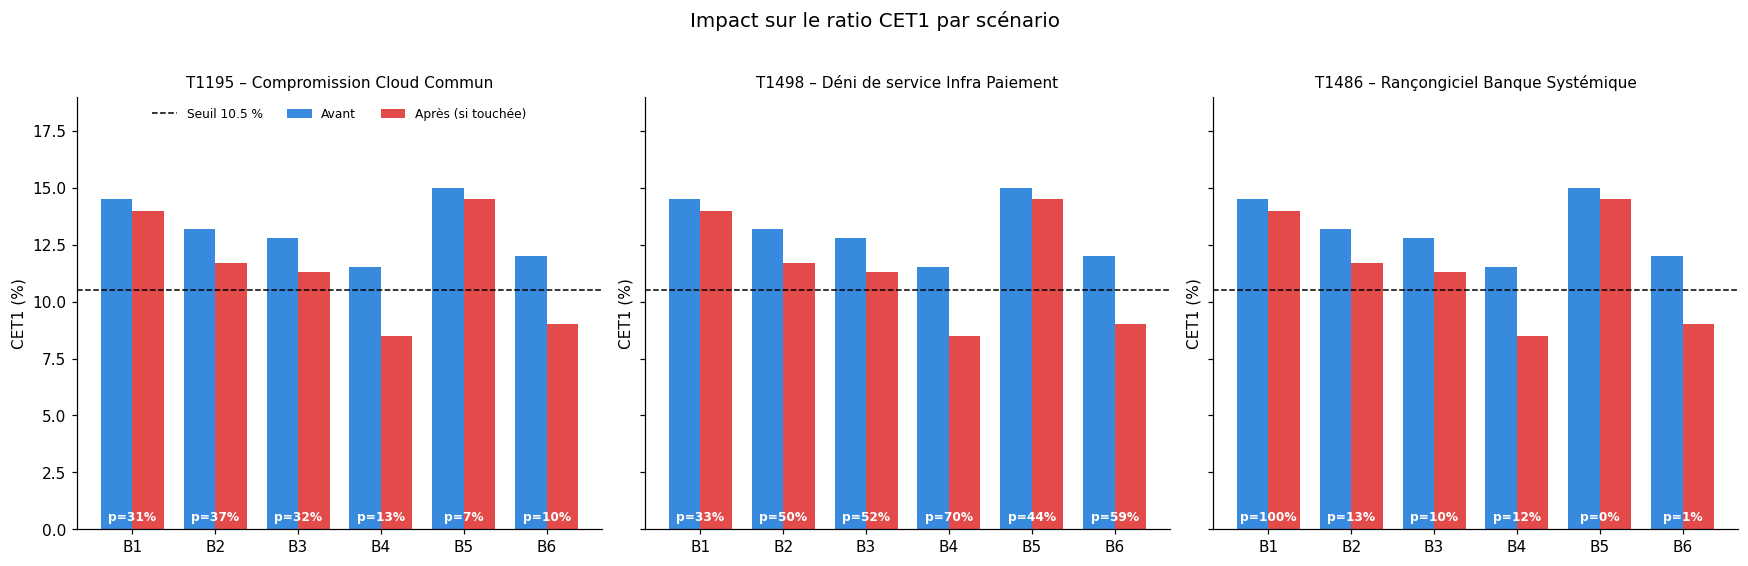

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
w = 0.38
for ax, (sid, df) in zip(axes, impacts.items()):
    x = np.arange(len(df))
    ax.bar(x - w/2, df.CET1_avant, w, label="Avant", color="#378ADD")
    ax.bar(x + w/2, df.CET1_apres, w, label="Après (si touchée)", color="#E24B4A")
    ax.axhline(SEUIL_CET1, color="black", ls="--", lw=1, label=f"Seuil {SEUIL_CET1} %")
    for xi, p in zip(x, df.proba_touchee):
        ax.text(xi, 0.4, f"p={p:.0%}", ha="center", fontsize=8, color="white", fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(df.banque)
    ax.set_title(scenarios[sid]["name"], fontsize=10)
    ax.set_ylabel("CET1 (%)")
axes[0].set_ylim(0, 19)
axes[0].legend(fontsize=8, loc="upper center", ncol=3, frameon=False)
plt.suptitle("Impact sur le ratio CET1 par scénario", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("figures/fig4_impact_cet1.png", dpi=200, bbox_inches="tight")
plt.show()

<a id="etape5"></a>
# Étape 5 — Sensibilité et recommandations

**Objectif.** Savoir **quelles hypothèses pèsent le plus** sur les résultats et **quelles mesures** réduisent le risque.

**Indicateur de résultat** : l'espérance du nombre de banques sous au moins un seuil (CET1 ou LCR). Il est calculé par la chaîne complète : simulation de la propagation, puis impact prudentiel. Comme toutes les simulations partagent la même graine, les écarts « avant / après » reflètent le changement testé et non du bruit aléatoire.

## 5.1 Fonction d'évaluation

In [22]:
def evaluer(G_var, noeud_choc):
    "Chaîne complète sur un graphe modifié : propagation puis espérance du nombre de banques sous seuil."
    taux = simuler(G_var, noeud_choc)["taux_contagion"]
    return nb_banques_sous_seuil(impact_scenario(G_var, taux, noeud_choc))

def evaluer_tous(G_var):
    "Évalue les 3 scénarios et renvoie un dict {scenario: indicateur}."
    return {sid: evaluer(G_var, sc["seed"]) for sid, sc in scenarios.items()}

reference = evaluer_tous(G)
print("Situation de référence (espérance du nombre de banques sous seuil) :")
for sid, v in reference.items():
    print(f"  {scenarios[sid]['name']:<45} {v:.2f}")

Situation de référence (espérance du nombre de banques sous seuil) :
  T1195 – Compromission Cloud Commun            0.23
  T1498 – Déni de service Infra Paiement        1.29
  T1486 – Rançongiciel Banque Systémique        0.12


## 5.2 Sensibilité à la substituabilité

On **décale** la substituabilité de chaque lien d'une même valeur Δ (bornée à [0, 1]) plutôt que de l'écraser par une valeur unique : on conserve ainsi l'hétérogénéité du réseau (liens financiers plus substituables que les liens de paiement).

In [23]:
def avec_substituabilite_decalee(G, delta):
    H = G.copy()
    for u, v in H.edges:
        H[u][v]["substitutability"] = float(np.clip(G[u][v]["substitutability"] + delta, 0, 1))
    return H

deltas = [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4]
sens_sub = pd.DataFrame(
    [{"delta_substituabilite": d, **evaluer_tous(avec_substituabilite_decalee(G, d))} for d in deltas]
).set_index("delta_substituabilite")
sens_sub.to_csv("data/sensibilite_substituabilite.csv")
sens_sub.round(2)

,T1195_cloud,T1498_pay,T1486_b1
delta_substituabilite,,,
-0.1,0.31,1.42,0.15
0.0,0.23,1.29,0.12
0.1,0.18,1.11,0.09
0.2,0.14,0.96,0.07
0.3,0.08,0.82,0.05
0.4,0.05,0.69,0.03


## 5.3 Sensibilité à la maturité cyber

On relève (ou dégrade) la maturité de **tous** les acteurs de δ niveaux, bornée à [1, 5].

> **Remarque de modélisation.** Dans ce modèle, la maturité n'agit que sur la **cible** d'une transmission (`vulnérabilité(v)`). Le nœud choc est compromis par hypothèse : améliorer sa propre maturité ne change rien au scénario qui le prend pour point de départ. Une mesure de maturité n'a d'effet que sur les nœuds situés en aval.

In [24]:
def avec_maturite_decalee(G, delta, noeuds=None):
    H = G.copy()
    for n in (noeuds or H.nodes):
        H.nodes[n]["maturity"] = int(np.clip(G.nodes[n]["maturity"] + delta, 1, 5))
    return H

boosts = [-1, 0, 1, 2]
sens_mat = pd.DataFrame(
    [{"delta_maturite": d, **evaluer_tous(avec_maturite_decalee(G, d))} for d in boosts]
).set_index("delta_maturite")
sens_mat.to_csv("data/sensibilite_maturite.csv")
sens_mat.round(2)

,T1195_cloud,T1498_pay,T1486_b1
delta_maturite,,,
-1,0.43,1.56,0.16
0,0.23,1.29,0.12
1,0.09,0.96,0.08
2,0.06,0.65,0.06


## 5.4 Test de deux mesures

| Mesure | Action | Raisonnement |
|---|---|---|
| **A — Diversifier le prestataire de paiement** | Substituabilité des liens PAY → banques portée à 0,45 (contre 0,1 à 0,2 aujourd'hui) | PAY est le SPOF le plus évident (étape 2) : on lui crée une alternative |
| **B — Renforcer la maturité des banques les plus fragiles** | Maturité de B4 et B6 portée de 2 à 4 | Ce sont les deux banques qui franchissent leur seuil (étape 4) ; leur maturité agit directement sur la probabilité qu'elles soient touchées |

On teste A seule, B seule, puis A + B, sur les trois scénarios.

In [25]:
# Mesure A : substituabilité PAY -> banques
G_A = G.copy()
for u, v in G_A.edges:
    if u == "PAY" and G_A.nodes[v]["type"] == "bank":
        G_A[u][v]["substitutability"] = 0.45

# Mesure B : maturité de B4 et B6 portée à 4
G_B = G.copy()
for b in ("B4", "B6"):
    G_B.nodes[b]["maturity"] = 4

# Combinaison A + B
G_AB = G_A.copy()
for b in ("B4", "B6"):
    G_AB.nodes[b]["maturity"] = 4

mesures = pd.DataFrame({
    "Référence":        reference,
    "A – Diversifier PAY": evaluer_tous(G_A),
    "B – Maturité B4/B6":  evaluer_tous(G_B),
    "A + B":            evaluer_tous(G_AB),
})
mesures.index = [scenarios[s]["name"] for s in mesures.index]
mesures.to_csv("data/effet_mesures.csv")
mesures.round(2)

,Référence,A – Diversifier PAY,B – Maturité B4/B6,A + B
T1195 – Compromission Cloud Commun,0.23,0.17,0.12,0.08
T1498 – Déni de service Infra Paiement,1.29,0.78,0.67,0.40
T1486 – Rançongiciel Banque Systémique,0.12,0.12,0.06,0.06


## 5.5 Visualisation (figure 5)

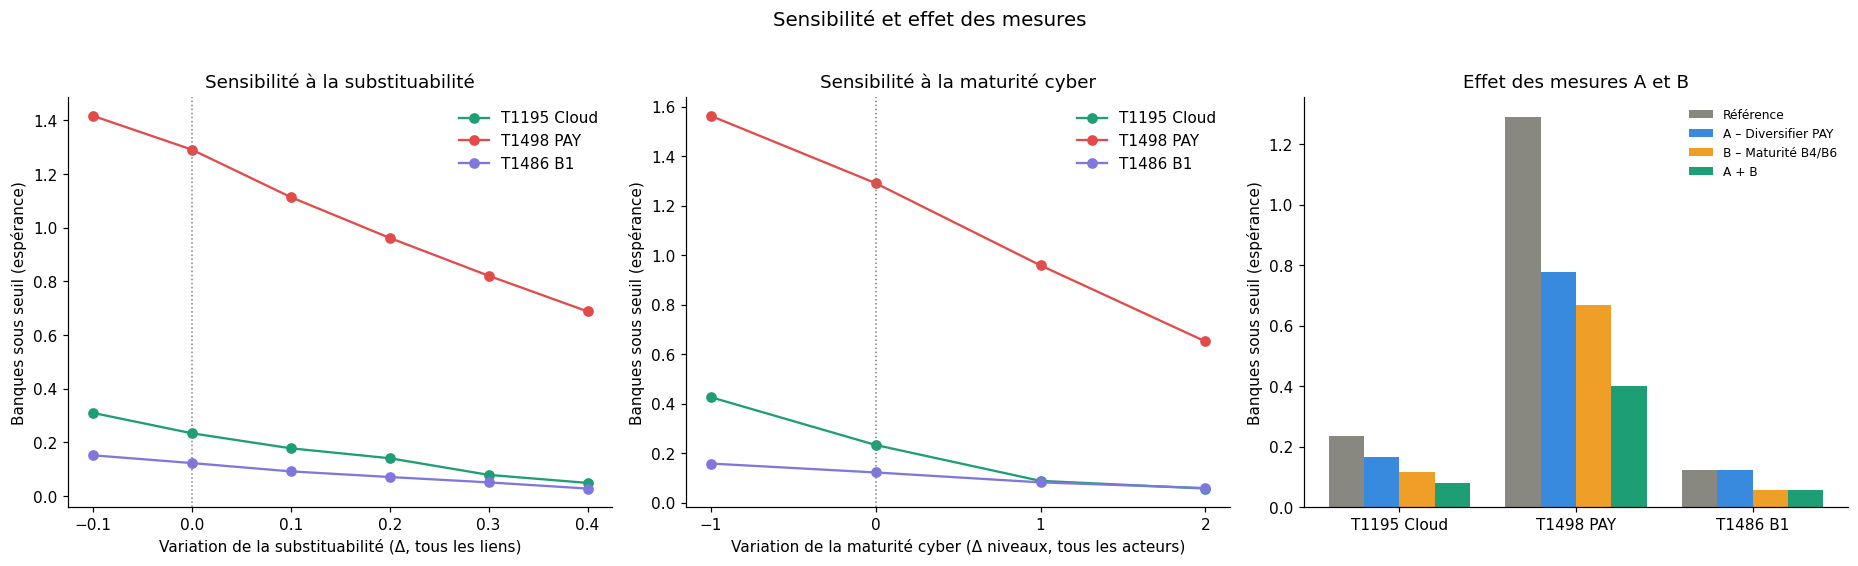

In [26]:
noms_courts = {"T1195_cloud": "T1195 Cloud", "T1498_pay": "T1498 PAY", "T1486_b1": "T1486 B1"}
couleurs_sc = {"T1195_cloud": "#1D9E75", "T1498_pay": "#E24B4A", "T1486_b1": "#7F77DD"}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for sid in scenarios:
    axes[0].plot(sens_sub.index, sens_sub[sid], "o-", label=noms_courts[sid], color=couleurs_sc[sid])
    axes[1].plot(sens_mat.index, sens_mat[sid], "o-", label=noms_courts[sid], color=couleurs_sc[sid])
axes[0].axvline(0, color="grey", ls=":", lw=1)
axes[1].axvline(0, color="grey", ls=":", lw=1)
axes[0].set_xlabel("Variation de la substituabilité (Δ, tous les liens)")
axes[0].set_title("Sensibilité à la substituabilité")
axes[1].set_xlabel("Variation de la maturité cyber (Δ niveaux, tous les acteurs)")
axes[1].set_xticks(sens_mat.index)
axes[1].set_title("Sensibilité à la maturité cyber")
for ax in axes[:2]:
    ax.set_ylabel("Banques sous seuil (espérance)")
    ax.legend(frameon=False)

x = np.arange(len(mesures)); w = 0.2
for i, col in enumerate(mesures.columns):
    axes[2].bar(x + (i - 1.5) * w, mesures[col], w, label=col,
                color=["#888780", "#378ADD", "#EF9F27", "#1D9E75"][i])
axes[2].set_xticks(x)
axes[2].set_xticklabels([noms_courts[s] for s in scenarios])
axes[2].set_ylabel("Banques sous seuil (espérance)")
axes[2].set_title("Effet des mesures A et B")
axes[2].legend(frameon=False, fontsize=8)

plt.suptitle("Sensibilité et effet des mesures", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("figures/fig5_sensibilite.png", dpi=200, bbox_inches="tight")
plt.show()

# Conclusions et recommandations

La synthèse ci-dessous est **générée à partir des résultats calculés** : elle reste cohérente si l'on modifie des paramètres et que l'on relance le notebook.

In [27]:
fr = lambda x, d=2: f"{x:.{d}f}".replace(".", ",")        # format français des décimales

pire = max(reference, key=reference.get)                   # scénario qui franchit le plus de seuils
prop = synth_prop["Banques touchées (espérance, sur 6)"].astype(float)
prop.index = list(scenarios)
plus_etendu = prop.idxmax()                                # scénario le plus étendu

fragiles = sorted(set().union(*[set(df.loc[df.franchit_CET1 | df.franchit_LCR, "banque"])
                                for df in impacts.values()]))
lcr_total = float(synth_impact["Banques sous seuil LCR (espérance)"].astype(float).sum())
phrase_lcr = ("Le LCR n'est jamais franchi avec la calibration retenue." if lcr_total == 0
              else f"Le LCR est aussi franchi (espérance cumulée : {fr(lcr_total)} banque).")

# Sensibilité sur le pire scénario
ref = reference[pire]
red_sub = 1 - sens_sub.loc[0.2, pire] / ref                # substituabilité +0,2
red_mat = 1 - sens_mat.loc[1, pire] / ref                  # maturité +1 niveau
if abs(red_sub - red_mat) < 0.10:
    verdict = "deux leviers d'ordre de grandeur comparable"
else:
    verdict = "le levier le plus puissant est " + ("la substituabilité" if red_sub > red_mat else "la maturité")

# Efficacité des mesures sur le pire scénario
lig = mesures.loc[scenarios[pire]["name"]]
red = {k: 1 - lig[k] / lig["Référence"] for k in ["A – Diversifier PAY", "B – Maturité B4/B6", "A + B"]}
meilleure_seule = max(["A – Diversifier PAY", "B – Maturité B4/B6"], key=lambda k: red[k])

lignes_mesures = "\n".join(
    f"| {n} | {fr(r.iloc[0])} | {fr(r.iloc[1])} | {fr(r.iloc[2])} | {fr(r.iloc[3])} |"
    for n, r in mesures.iterrows())

txt = f'''
### Résultats clés

- **Structure.** PAY (7 des 12 liens critiques) et CLD1 concentrent le risque ; TEL1 et TEL2 sont des risques cachés (ils atteignent les 6 banques par chaînage) ; IT1 est un angle mort (5 banques atteignables, aucun SPOF).
- **Propagation.** Le scénario le plus étendu est **{scenarios[plus_etendu]['name']}** (≈ {fr(prop[plus_etendu], 1)} banques touchées en espérance).
- **Impact prudentiel.** Le scénario qui fait franchir le plus de seuils est **{scenarios[pire]['name']}** : {fr(ref)} banque(s) sous seuil en espérance. Les franchissements concernent les banques à faible marge de CET1 et à RTO long ({", ".join(fragiles)}). {phrase_lcr}
- **Sensibilité** (sur ce scénario). Une hausse de 0,2 de la substituabilité réduit l'indicateur de {red_sub:.0%} ; un niveau de maturité cyber en plus pour tous les acteurs le réduit de {red_mat:.0%} : {verdict}.

### Effet des mesures (espérance du nombre de banques sous seuil)

| Scénario | Référence | A – Diversifier PAY | B – Maturité B4/B6 | A + B |
|---|---|---|---|---|
{lignes_mesures}

Sur **{scenarios[pire]['name']}**, la mesure A seule réduit l'indicateur de {red["A – Diversifier PAY"]:.0%}, la mesure B seule de {red["B – Maturité B4/B6"]:.0%} (la plus efficace seule : **{meilleure_seule}**), et leur combinaison de {red["A + B"]:.0%}.

### Recommandations

1. **Traiter PAY en priorité** : c'est le nœud qui porte le plus de liens critiques et il est à l'origine du scénario le plus dangereux. Lui créer une voie de contournement réduit l'indicateur de {red["A – Diversifier PAY"]:.0%} sur ce scénario.
2. **Cibler les banques fragiles** ({", ".join(fragiles)} : faible marge de CET1, RTO de 24 h) : relever leur maturité réduit l'indicateur de {red["B – Maturité B4/B6"]:.0%} ; raccourcir leur RTO agirait sur la gravité du franchissement, ce que ce notebook ne teste pas.
3. **Combiner les leviers** : A + B réduit l'indicateur de {red["A + B"]:.0%}, plus que chaque mesure seule.
4. **Surveiller les risques cachés** (TEL1, TEL2, IT1) que les indicateurs de SPOF seuls ne détectent pas.
'''
display(Markdown(txt))


### Résultats clés

- **Structure.** PAY (7 des 12 liens critiques) et CLD1 concentrent le risque ; TEL1 et TEL2 sont des risques cachés (ils atteignent les 6 banques par chaînage) ; IT1 est un angle mort (5 banques atteignables, aucun SPOF).
- **Propagation.** Le scénario le plus étendu est **T1498 – Déni de service Infra Paiement** (≈ 3,1 banques touchées en espérance).
- **Impact prudentiel.** Le scénario qui fait franchir le plus de seuils est **T1498 – Déni de service Infra Paiement** : 1,29 banque(s) sous seuil en espérance. Les franchissements concernent les banques à faible marge de CET1 et à RTO long (B4, B6). Le LCR n'est jamais franchi avec la calibration retenue.
- **Sensibilité** (sur ce scénario). Une hausse de 0,2 de la substituabilité réduit l'indicateur de 25% ; un niveau de maturité cyber en plus pour tous les acteurs le réduit de 26% : deux leviers d'ordre de grandeur comparable.

### Effet des mesures (espérance du nombre de banques sous seuil)

| Scénario | Référence | A – Diversifier PAY | B – Maturité B4/B6 | A + B |
|---|---|---|---|---|
| T1195 – Compromission Cloud Commun | 0,23 | 0,17 | 0,12 | 0,08 |
| T1498 – Déni de service Infra Paiement | 1,29 | 0,78 | 0,67 | 0,40 |
| T1486 – Rançongiciel Banque Systémique | 0,12 | 0,12 | 0,06 | 0,06 |

Sur **T1498 – Déni de service Infra Paiement**, la mesure A seule réduit l'indicateur de 40%, la mesure B seule de 48% (la plus efficace seule : **B – Maturité B4/B6**), et leur combinaison de 69%.

### Recommandations

1. **Traiter PAY en priorité** : c'est le nœud qui porte le plus de liens critiques et il est à l'origine du scénario le plus dangereux. Lui créer une voie de contournement réduit l'indicateur de 40% sur ce scénario.
2. **Cibler les banques fragiles** (B4, B6 : faible marge de CET1, RTO de 24 h) : relever leur maturité réduit l'indicateur de 48% ; raccourcir leur RTO agirait sur la gravité du franchissement, ce que ce notebook ne teste pas.
3. **Combiner les leviers** : A + B réduit l'indicateur de 69%, plus que chaque mesure seule.
4. **Surveiller les risques cachés** (TEL1, TEL2, IT1) que les indicateurs de SPOF seuls ne détectent pas.


## Hypothèses et limites

**Hypothèses principales**
- Données entièrement simulées (16 nœuds, 38 liens), sans calibrage empirique.
- Probabilité de transmission = dépendance × (1 − substituabilité) × vulnérabilité ; vulnérabilité linéaire en la maturité.
- Transmissions indépendantes entre arcs ; le nœud choc est compromis avec certitude.
- Durée d'indisponibilité = max(RTO du nœud choc, RTO de la banque), traduite en pertes par une table à 5 paliers.
- Seuils simplifiés : CET1 < 10,5 %, LCR < 100 %.

**Limites**
- **Pas de canal de confiance** : les retraits de dépôts ne dépendent que de la durée d'indisponibilité, pas de la perception du marché ni d'un effet de panique.
- **LCR très simplifié** : les retraits réduisent le ratio proportionnellement, sans modéliser les actifs liquides ni les flux sortants.
- **Pas de comportement adaptatif** (reprise, bascule vers un prestataire de secours, intervention d'une autorité) et pas de corrélation entre chocs.
- **Scénarios testés isolément** : pas de multi-chocs simultanés.
- **Bruit de simulation** : 1 000 tirages donnent une précision de l'ordre de ±3 points sur un taux de contagion ; les résultats comparent surtout des ordres de grandeur.
- **Effet de seuil** : la table à paliers crée des discontinuités (une banque à 23 h ou à 25 h d'arrêt ne subit pas la même perte).


## Annexe — Livrables produits par ce notebook

| Fichier | Contenu |
|---|---|
| `data/nodes.csv`, `data/links.csv` | Nœuds et liens du système |
| `data/structure_metrics.csv`, `data/spof.csv` | Métriques de structure et liens critiques |
| `data/contagion_<scénario>.csv` | Taux de contagion et délai moyen par nœud |
| `data/banks_balance.csv` | Bilans fictifs des banques |
| `data/impact_<scénario>.csv`, `data/impact_all_scenarios.csv`, `data/impact_synthese.csv` | Impact CET1 / LCR |
| `data/sensibilite_*.csv`, `data/effet_mesures.csv` | Sensibilité et comparaison des mesures |
| `figures/fig1_graphe.png` | Cartographie |
| `figures/fig2_structure.png` | Métriques de structure |
| `figures/fig3_contagion.png` | Contagion par scénario |
| `figures/fig4_impact_cet1.png` | Impact sur le CET1 |
| `figures/fig5_sensibilite.png` | Sensibilité et mesures |

